# Random Forest Classification Lab

### Aim
To build a **Random Forest Classifier** on the Insurance dataset and compare the effect of:

1. Different **tree heights** (`max_depth`)
2. Different **numbers of trees** (`n_estimators`)

We will compare the models using **Accuracy, Precision, and Recall** and draw graphs.

> **Note:** The original Insurance dataset has `charges` as a continuous value. For this classification lab, we create a simple target called `high_charges`:  
> **1 = charges are above the median** and **0 = charges are at or below the median.**


In [3]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

print("Libraries imported successfully")


Libraries imported successfully


In [4]:
# Load the dataset
df = pd.read_csv("insurance.csv")

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
# Basic information
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
None

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


## 1. Prepare the data

In [6]:
# Create classification target
# 1 = high charges, 0 = low charges
median_charges = df["charges"].median()
df["high_charges"] = (df["charges"] > median_charges).astype(int)

print("Median charges:", median_charges)
print("\nTarget distribution:")
print(df["high_charges"].value_counts())


Median charges: 9382.033

Target distribution:
high_charges
1    669
0    669
Name: count, dtype: int64


In [7]:
# Convert text columns into numbers
data = df.copy()

le = LabelEncoder()

data["sex"] = le.fit_transform(data["sex"])
data["smoker"] = le.fit_transform(data["smoker"])
data["region"] = le.fit_transform(data["region"])

# Features and target
X = data.drop(["charges", "high_charges"], axis=1)
y = data["high_charges"]

print("Features:")
print(X.head())


Features:
   age  sex     bmi  children  smoker  region
0   19    0  27.900         0       1       3
1   18    1  33.770         1       0       2
2   28    1  33.000         3       0       2
3   33    1  22.705         0       0       1
4   32    1  28.880         0       0       1


In [8]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (1070, 6)
Testing data: (268, 6)


## 2. Random Forest with different tree heights

`max_depth` controls how deep each decision tree can grow.

We will try:

- Depth = 2
- Depth = 4
- Depth = 6
- Depth = 8
- Depth = 10


In [9]:
# Try different tree heights
depths = [2, 4, 6, 8, 10]

depth_results = []

for depth in depths:
    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    depth_results.append({
        "Max Depth": depth,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred)
    })

depth_results = pd.DataFrame(depth_results)
depth_results


,Max Depth,Accuracy,Precision,Recall
0,2,0.932836,0.960317,0.902985
1,4,0.932836,0.960317,0.902985
2,6,0.932836,0.967742,0.895522
3,8,0.936567,0.975610,0.895522
4,10,0.936567,0.968000,0.902985


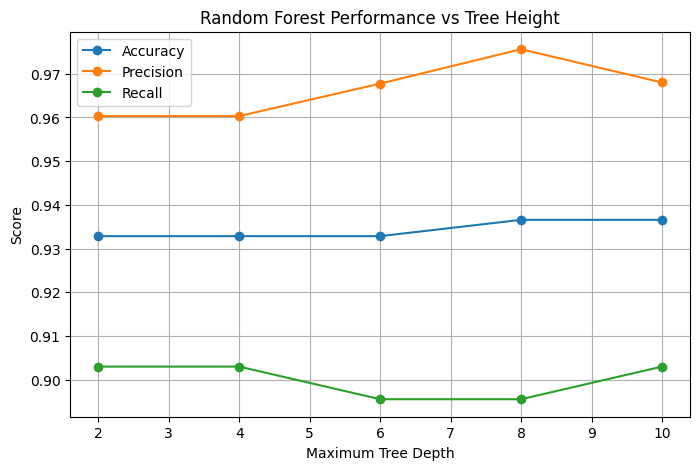

In [10]:
# Graph: performance for different tree heights
plt.figure(figsize=(8, 5))

plt.plot(depth_results["Max Depth"], depth_results["Accuracy"], marker="o", label="Accuracy")
plt.plot(depth_results["Max Depth"], depth_results["Precision"], marker="o", label="Precision")
plt.plot(depth_results["Max Depth"], depth_results["Recall"], marker="o", label="Recall")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Score")
plt.title("Random Forest Performance vs Tree Height")
plt.legend()
plt.grid(True)
plt.show()


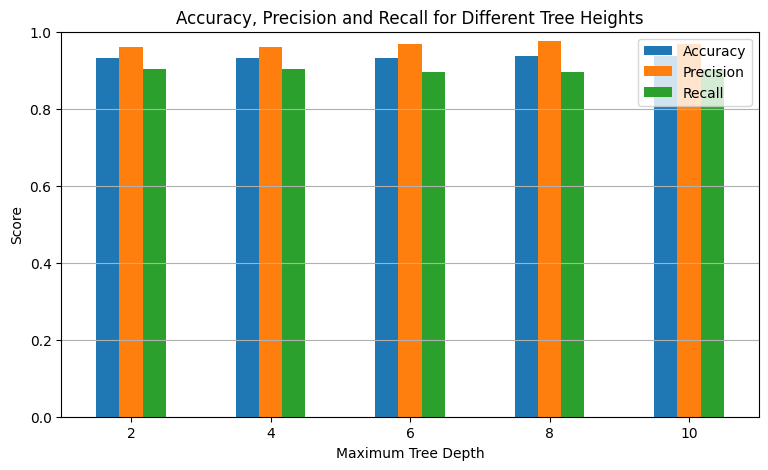

In [11]:
# Bar graph for different tree heights
depth_results.set_index("Max Depth")[["Accuracy", "Precision", "Recall"]].plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Accuracy, Precision and Recall for Different Tree Heights")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()


## 3. Random Forest with different numbers of trees

`n_estimators` tells the Random Forest how many decision trees to use.

We will try:

- 10 trees
- 50 trees
- 100 trees
- 150 trees
- 200 trees


In [12]:
# Try different numbers of trees
tree_numbers = [10, 50, 100, 150, 200]

tree_results = []

for n in tree_numbers:
    model = RandomForestClassifier(
        n_estimators=n,
        max_depth=6,
        random_state=42
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    tree_results.append({
        "Number of Trees": n,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred)
    })

tree_results = pd.DataFrame(tree_results)
tree_results


,Number of Trees,Accuracy,Precision,Recall
0,10,0.936567,0.975610,0.895522
1,50,0.932836,0.960317,0.902985
2,100,0.932836,0.967742,0.895522
3,150,0.932836,0.960317,0.902985
4,200,0.929104,0.952756,0.902985


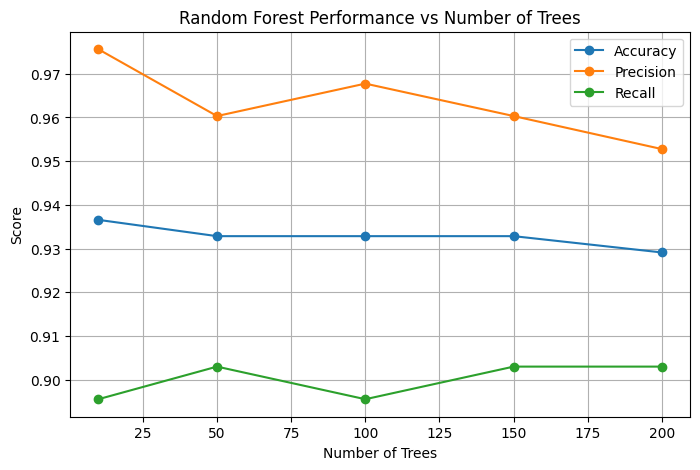

In [13]:
# Graph: performance for different numbers of trees
plt.figure(figsize=(8, 5))

plt.plot(tree_results["Number of Trees"], tree_results["Accuracy"], marker="o", label="Accuracy")
plt.plot(tree_results["Number of Trees"], tree_results["Precision"], marker="o", label="Precision")
plt.plot(tree_results["Number of Trees"], tree_results["Recall"], marker="o", label="Recall")

plt.xlabel("Number of Trees")
plt.ylabel("Score")
plt.title("Random Forest Performance vs Number of Trees")
plt.legend()
plt.grid(True)
plt.show()


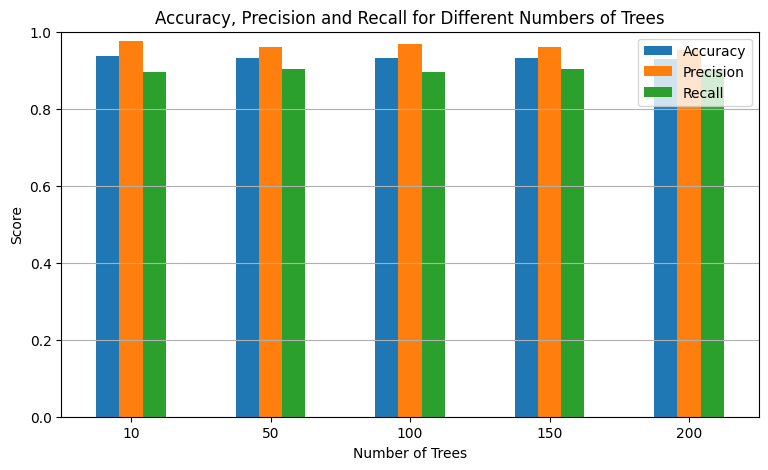

In [14]:
# Bar graph for different numbers of trees
tree_results.set_index("Number of Trees")[["Accuracy", "Precision", "Recall"]].plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Accuracy, Precision and Recall for Different Numbers of Trees")
plt.xlabel("Number of Trees")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()


## 4. Final comparison

Now we compare the best results from the two experiments.

In [15]:
# Best result for tree height
best_depth = depth_results.loc[depth_results["Accuracy"].idxmax()]

# Best result for number of trees
best_tree = tree_results.loc[tree_results["Accuracy"].idxmax()]

print("Best Tree Height Result:")
print(best_depth)

print("\nBest Number of Trees Result:")
print(best_tree)


Best Tree Height Result:
Max Depth    8.000000
Accuracy     0.936567
Precision    0.975610
Recall       0.895522
Name: 3, dtype: float64

Best Number of Trees Result:
Number of Trees    10.000000
Accuracy            0.936567
Precision           0.975610
Recall              0.895522
Name: 0, dtype: float64


In [16]:
# Final Random Forest model
final_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    random_state=42
)

final_model.fit(X_train, y_train)
final_pred = final_model.predict(X_test)

print("Final Model Results")
print("-------------------")
print("Accuracy :", round(accuracy_score(y_test, final_pred), 4))
print("Precision:", round(precision_score(y_test, final_pred), 4))
print("Recall   :", round(recall_score(y_test, final_pred), 4))


Final Model Results
-------------------
Accuracy : 0.9328
Precision: 0.9677
Recall   : 0.8955


## Conclusion

- **Accuracy** tells us how many predictions were correct overall.
- **Precision** tells us how many predicted high-charge cases were actually high-charge cases.
- **Recall** tells us how many actual high-charge cases were correctly found.
- Increasing tree depth can make the model more flexible, but very deep trees can overfit.
- Increasing the number of trees generally makes the Random Forest more stable, although it also increases computation time.

### Result
The experiments above show how changing **tree height** and **number of trees** affects Random Forest classification performance on the Insurance dataset.
